# Data Augmentation — NIH Chest X-Ray

  - Rotación leve (RandomRotation(5-10°)) — las radiografías pueden tener ligera rotación del paciente
  - Traslación leve (RandomAffine(translate=(0.05, 0.05))) — ligero descentramiento
  - Escalado leve (RandomResizedCrop con scale 0.9-1.0) — variación de distancia al tubo
  - Ajuste de brillo/contraste (ColorJitter(brightness=0.1, contrast=0.1)) — variación de exposición

Es va split per train/test a nivell de pacient per evitar data leakage. Test no te data augmentation mentre que train si


In [21]:
import os
import shutil
import random
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torchvision.transforms as T
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

/home/joanguest/Documents/TFM/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuració

Modifica les variables d'aquesta cel·la per ajustar el comportament del notebook.

In [22]:
# --- Paths ---
ROOT = Path("../data")
SRC_DIR        = ROOT / "NIH_Chest_XRAY"
SRC_IMAGES_DIR = SRC_DIR / "sel_images"
SRC_CSV        = SRC_DIR / "experiment_data.csv"

DST_DIR        = ROOT / "NIH_Chest_XRAY_augmented"
DST_TRAIN_DIR  = DST_DIR / "train"
DST_TEST_DIR   = DST_DIR / "test"

# --- Split ---
TEST_SIZE      = 0.2   # Proporció del conjunt de test (sobre pacients únics)
RANDOM_SEED    = 42

# --- Augmentació ---
N_AUG_PER_IMAGE = 2    # Nombre de còpies augmentades per cada imatge de train
                       # (0 = no augmentació, només còpia original)

# Paràmetres de les transformacions
ROTATION_DEGREES     = (5, 10)       # rang de graus per RandomRotation
TRANSLATE            = (0.05, 0.05)  # fracció max de la mida per RandomAffine
RESIZED_CROP_SCALE   = (0.9, 1.0)   # rang d'escala per RandomResizedCrop
BRIGHTNESS_JITTER    = 0.1           # variació de brillantor
CONTRAST_JITTER      = 0.1           # variació de contrast

print(f"Test size: {TEST_SIZE:.0%} dels pacients")
print(f"Augmentaciones per imatge de train: {N_AUG_PER_IMAGE}")

Test size: 20% dels pacients
Augmentaciones per imatge de train: 2


## 1. Carregar i explorar les metadades

In [23]:
df = pd.read_csv(SRC_CSV)

# Extreure patient_id dels 8 primers dígits del nom de fitxer
df["patient_id"] = df["image"].str[:8]

# Verificar que totes les imatges existeixen
missing = [img for img in df["image"] if not (SRC_IMAGES_DIR / img).exists()]
if missing:
    print(f"AVÍS: {len(missing)} imatges no trobades: {missing[:5]}")
else:
    print(f"Totes les {len(df)} imatges trobades correctament.")

df.head()

Totes les 2287 imatges trobades correctament.


,image,age,gender,view_pos,img_width,img_height,spacing_x,spacing_y,class,patient_id
0,00010633_000.png,59,1,PA,2574,2991,0.143000,0.143000,0,00010633
1,00029808_003.png,32,0,PA,2021,2021,0.194311,0.194311,1,00029808
2,00022290_015.png,58,0,AP,3056,2544,0.139000,0.139000,1,00022290
3,00013474_000.png,12,0,PA,2562,2521,0.143000,0.143000,0,00013474
4,00020171_000.png,50,1,AP,3056,2544,0.139000,0.139000,1,00020171


In [24]:
# Mapa de valors llegibles
gender_map = {0: "Female", 1: "Male"}
class_map  = {0: "No Finding", 1: "Pathology"}

print(f"Total imatges:   {len(df)}")
print(f"Pacients únics:  {df['patient_id'].nunique()}")
print()
print("Distribució de classe:")
print(df["class"].map(class_map).value_counts().to_string())
print()
print("Distribució de gènere:")
print(df["gender"].map(gender_map).value_counts().to_string())
print()
print("Distribució classe × gènere:")
print(df.groupby(["class", "gender"]).size().rename(index={**class_map, **gender_map}).to_string())

Total imatges:   2287
Pacients únics:  2287

Distribució de classe:
class
No Finding    1279
Pathology     1008

Distribució de gènere:
gender
Female    1221
Male      1066

Distribució classe × gènere:
class   gender
Female  Female    633
        Male      646
Male    Female    588
        Male      420


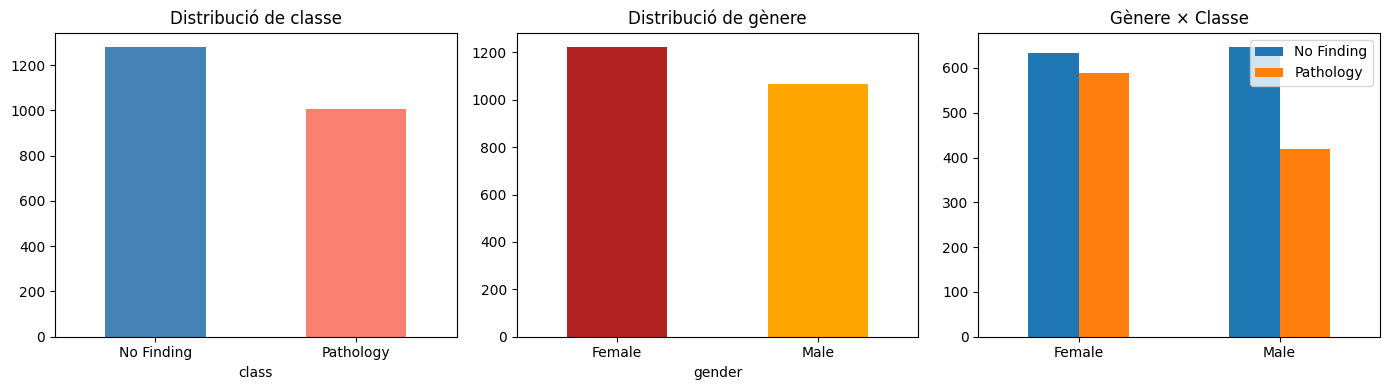

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

df["class"].map(class_map).value_counts().plot(kind="bar", ax=axes[0], color=["steelblue", "salmon"])
axes[0].set_title("Distribució de classe")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

df["gender"].map(gender_map).value_counts().plot(kind="bar", ax=axes[1], color=["firebrick", "orange"])
axes[1].set_title("Distribució de gènere")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)

cross = df.groupby(["gender", "class"]).size().unstack()
cross.index = [gender_map[i] for i in cross.index]
cross.columns = [class_map[c] for c in cross.columns]
cross.plot(kind="bar", ax=axes[2])
axes[2].set_title("Gènere × Classe")
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

## 2. Split a nivell de pacient (sense data leakage)

El split es fa sobre els **pacients únics** (no sobre les imatges), de manera que totes les imatges d'un pacient queden al mateix conjunt.

In [26]:
# Resum per pacient: classe majoritària i gènere (per estratificar)
patients_df = (
    df.groupby("patient_id")
    .agg(
        gender=("gender", "first"),
        majority_class=("class", lambda x: x.mode()[0]),
        n_images=("image", "count"),
    )
    .reset_index()
)

# Estratificar per classe majoritària × gènere
patients_df["strat_key"] = patients_df["majority_class"].astype(str) + "_" + patients_df["gender"].astype(str)

train_patients, test_patients = train_test_split(
    patients_df["patient_id"].values,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=patients_df["strat_key"].values,
)

train_patients = set(train_patients)
test_patients  = set(test_patients)

df_train = df[df["patient_id"].isin(train_patients)].copy().reset_index(drop=True)
df_test  = df[df["patient_id"].isin(test_patients)].copy().reset_index(drop=True)

# Verificació: cap pacient compartit
assert len(train_patients & test_patients) == 0, "DATA LEAKAGE DETECTAT!"
assert len(df_train) + len(df_test) == len(df), "Pèrdua d'imatges en el split!"

print(f"Pacients train: {len(train_patients):4d}  |  Imatges train: {len(df_train):5d}")
print(f"Pacients test:  {len(test_patients):4d}  |  Imatges test:  {len(df_test):5d}")
print(f"Proporció test real: {len(df_test)/len(df):.1%}")

Pacients train: 1829  |  Imatges train:  1829
Pacients test:   458  |  Imatges test:    458
Proporció test real: 20.0%


In [27]:
# Verificar que la distribució de classe i gènere és similar entre splits
print("Distribució classe:")
print(pd.DataFrame({
    "Train": df_train["class"].map(class_map).value_counts(normalize=True),
    "Test":  df_test["class"].map(class_map).value_counts(normalize=True),
}).round(3))
print()
print("Distribució gènere:")
print(pd.DataFrame({
    "Train": df_train["gender"].map(gender_map).value_counts(normalize=True),
    "Test":  df_test["gender"].map(gender_map).value_counts(normalize=True),
}).round(3))

Distribució classe:
            Train   Test
class                   
No Finding  0.559  0.559
Pathology   0.441  0.441

Distribució gènere:
        Train   Test
gender              
Female  0.534  0.535
Male    0.466  0.465


## 3. Definir el pipeline d'augmentació

In [28]:
def build_augmentation_transform(img_size: tuple[int, int]) -> T.Compose:
    """
    Construeix el pipeline d'augmentació per a una imatge de mida `img_size` (H, W).
    S'usa img_size per assegurar que RandomResizedCrop retorna la mida original.
    """
    return T.Compose([
        T.RandomRotation(degrees=ROTATION_DEGREES),
        T.RandomAffine(degrees=0, translate=TRANSLATE),
        T.RandomResizedCrop(size=img_size, scale=RESIZED_CROP_SCALE, antialias=True),
        T.ColorJitter(brightness=BRIGHTNESS_JITTER, contrast=CONTRAST_JITTER),
    ])


def augment_and_save(src_path: Path, dst_path: Path, aug_index: int):
    """Obre una imatge, aplica augmentació i guarda el resultat."""
    with Image.open(src_path) as img:
        img = img.convert("L")  # assegurar escala de grisos (radiografia)
        transform = build_augmentation_transform((img.height, img.width))
        aug_img = transform(img)
        aug_img.save(dst_path)

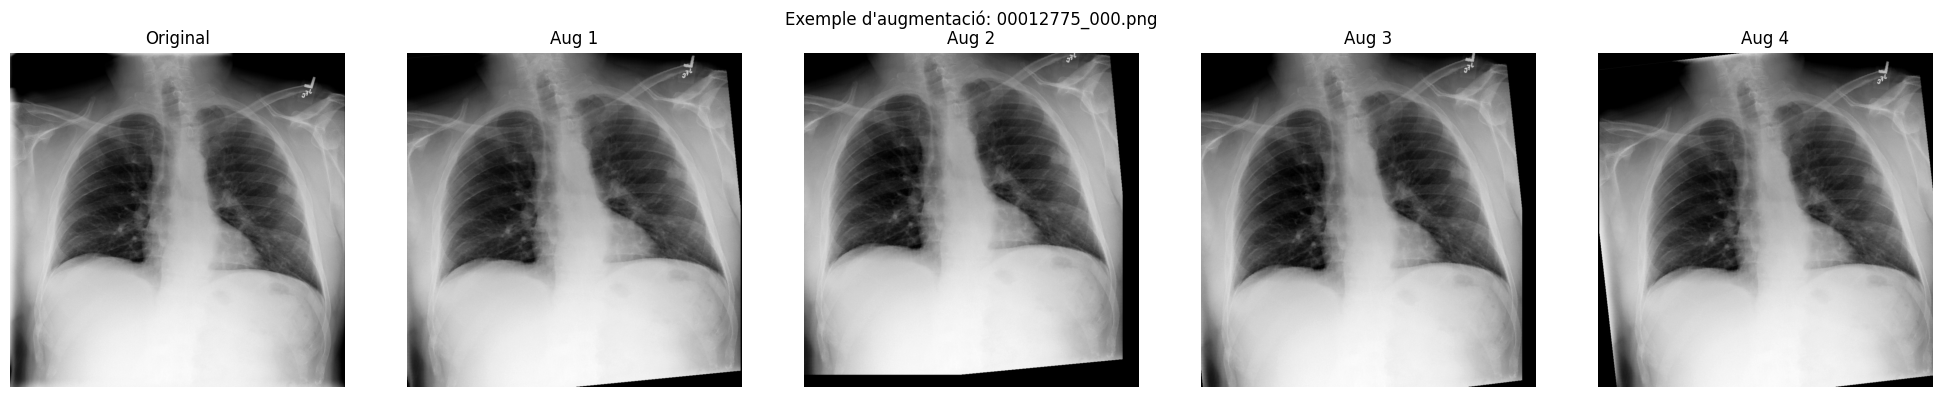

In [29]:
# Previsualitzar l'efecte de l'augmentació sobre una imatge aleatòria
random.seed(RANDOM_SEED)
sample_img_name = random.choice(df_train["image"].tolist())
sample_path = SRC_IMAGES_DIR / sample_img_name

with Image.open(sample_path) as img:
    img = img.convert("L")
    transform = build_augmentation_transform((img.height, img.width))

    n_preview = 4
    fig, axes = plt.subplots(1, n_preview + 1, figsize=(4 * (n_preview + 1), 4))

    axes[0].imshow(img, cmap="gray")
    axes[0].set_title("Original")
    axes[0].axis("off")

    for i in range(n_preview):
        aug = transform(img)
        axes[i + 1].imshow(aug, cmap="gray")
        axes[i + 1].set_title(f"Aug {i+1}")
        axes[i + 1].axis("off")

plt.suptitle(f"Exemple d'augmentació: {sample_img_name}", fontsize=12)
plt.tight_layout()
plt.show()

## 4. Crear el dataset augmentat a disc

**Estructura de sortida:**
```
data/NIH_Chest_XRAY_augmented/
├── train/
│   ├── 00010633_000.png          (original)
│   ├── 00010633_000_aug1.png     (augmentat)
│   ├── 00010633_000_aug2.png     (augmentat)
│   └── ...
├── test/
│   └── *.png                     (originals, sense augmentació)
├── train_metadata.csv
└── test_metadata.csv
```

In [30]:
# Crear directoris de sortida (esborra i torna a crear si ja existien)
if DST_DIR.exists():
    print(f"Esborro directori existent: {DST_DIR}")
    shutil.rmtree(DST_DIR)

DST_TRAIN_DIR.mkdir(parents=True, exist_ok=True)
DST_TEST_DIR.mkdir(parents=True, exist_ok=True)

print(f"Directoris creats:")
print(f"  {DST_TRAIN_DIR}")
print(f"  {DST_TEST_DIR}")

Esborro directori existent: ../data/NIH_Chest_XRAY_augmented
Directoris creats:
  ../data/NIH_Chest_XRAY_augmented/train
  ../data/NIH_Chest_XRAY_augmented/test


In [31]:
# --- Copiar imatges de TEST (sense augmentació) ---
print("Copiant imatges de test...")
for img_name in tqdm(df_test["image"], desc="Test"):
    shutil.copy2(SRC_IMAGES_DIR / img_name, DST_TEST_DIR / img_name)

print(f"Test: {len(df_test)} imatges copiades a {DST_TEST_DIR}")

Copiant imatges de test...


Test: 100%|██████████| 458/458 [00:00<00:00, 684.94it/s]

Test: 458 imatges copiades a ../data/NIH_Chest_XRAY_augmented/test


In [32]:
# --- Copiar originals + generar augmentades per TRAIN ---
aug_records = []  # metadades de les imatges augmentades

print(f"Copiant originals i generant {N_AUG_PER_IMAGE} augmentació(ns) per imatge...")

for _, row in tqdm(df_train.iterrows(), total=len(df_train), desc="Train"):
    img_name = row["image"]
    src_path = SRC_IMAGES_DIR / img_name

    # 1. Copiar original
    shutil.copy2(src_path, DST_TRAIN_DIR / img_name)

    # 2. Generar còpies augmentades
    stem = Path(img_name).stem  # e.g. "00010633_000"
    ext  = Path(img_name).suffix  # e.g. ".png"

    for i in range(1, N_AUG_PER_IMAGE + 1):
        aug_name = f"{stem}_aug{i}{ext}"
        dst_path = DST_TRAIN_DIR / aug_name
        augment_and_save(src_path, dst_path, aug_index=i)

        aug_records.append({
            **row.to_dict(),
            "image": aug_name,
            "augmented": True,
            "source_image": img_name,
        })

n_train_files = len(list(DST_TRAIN_DIR.glob("*.png")))
print(f"Train: {n_train_files} imatges ({len(df_train)} originals + {len(aug_records)} augmentades)")

Copiant originals i generant 2 augmentació(ns) per imatge...


Train: 100%|██████████| 1829/1829 [09:32<00:00,  3.19it/s]

Train: 5487 imatges (1829 originals + 3658 augmentades)


## 5. Guardar les metadades

In [33]:
# Construir DataFrame de train complet (originals + augmentades)
df_train_orig = df_train.copy()
df_train_orig["augmented"] = False
df_train_orig["source_image"] = df_train_orig["image"]

df_aug = pd.DataFrame(aug_records)
df_train_full = pd.concat([df_train_orig, df_aug], ignore_index=True)

# Dataset de test (sense augmentació)
df_test_out = df_test.copy()
df_test_out["augmented"] = False
df_test_out["source_image"] = df_test_out["image"]

# Guardar CSVs
df_train_full.to_csv(DST_DIR / "train_metadata.csv", index=False)
df_test_out.to_csv(DST_DIR / "test_metadata.csv", index=False)

print(f"Metadades guardades a {DST_DIR}")
print(f"  train_metadata.csv: {len(df_train_full)} registres")
print(f"  test_metadata.csv:  {len(df_test_out)} registres")

Metadades guardades a ../data/NIH_Chest_XRAY_augmented
  train_metadata.csv: 5487 registres
  test_metadata.csv:  458 registres


## 6. Resum i validació final

In [34]:
# Verificar consistència fitxers ↔ metadades
train_files_on_disk = set(p.name for p in DST_TRAIN_DIR.glob("*.png"))
train_files_in_csv  = set(df_train_full["image"])
test_files_on_disk  = set(p.name for p in DST_TEST_DIR.glob("*.png"))
test_files_in_csv   = set(df_test_out["image"])

assert train_files_on_disk == train_files_in_csv, \
    f"Inconsistència en train: {train_files_on_disk ^ train_files_in_csv}"
assert test_files_on_disk == test_files_in_csv, \
    f"Inconsistència en test: {test_files_on_disk ^ test_files_in_csv}"

print("Validació OK: fitxers i metadades consistents.\n")

print("=" * 55)
print("RESUM DEL DATASET AUGMENTAT")
print("=" * 55)
print(f"Font:          {SRC_DIR}")
print(f"Destí:         {DST_DIR}")
print(f"Test size:     {TEST_SIZE:.0%} dels pacients")
print(f"Aug/imatge:    {N_AUG_PER_IMAGE}")
print("-" * 55)
print(f"Pacients train: {len(train_patients):4d}  |  Imatges train: {len(df_train_full):5d}")
print(f"Pacients test:  {len(test_patients):4d}  |  Imatges test:  {len(df_test_out):5d}")
print(f"Factor ampliació train: {len(df_train_full)/len(df_train):.1f}×")
print("-" * 55)
print("Distribució classe (train augmentat):")
print(df_train_full["class"].map(class_map).value_counts().to_string())
print()
print("Distribució gènere (train augmentat):")
print(df_train_full["gender"].map(gender_map).value_counts().to_string())
print("=" * 55)

Validació OK: fitxers i metadades consistents.

RESUM DEL DATASET AUGMENTAT
Font:          ../data/NIH_Chest_XRAY
Destí:         ../data/NIH_Chest_XRAY_augmented
Test size:     20% dels pacients
Aug/imatge:    2
-------------------------------------------------------
Pacients train: 1829  |  Imatges train:  5487
Pacients test:   458  |  Imatges test:    458
Factor ampliació train: 3.0×
-------------------------------------------------------
Distribució classe (train augmentat):
class
No Finding    3069
Pathology     2418

Distribució gènere (train augmentat):
gender
Female    2928
Male      2559


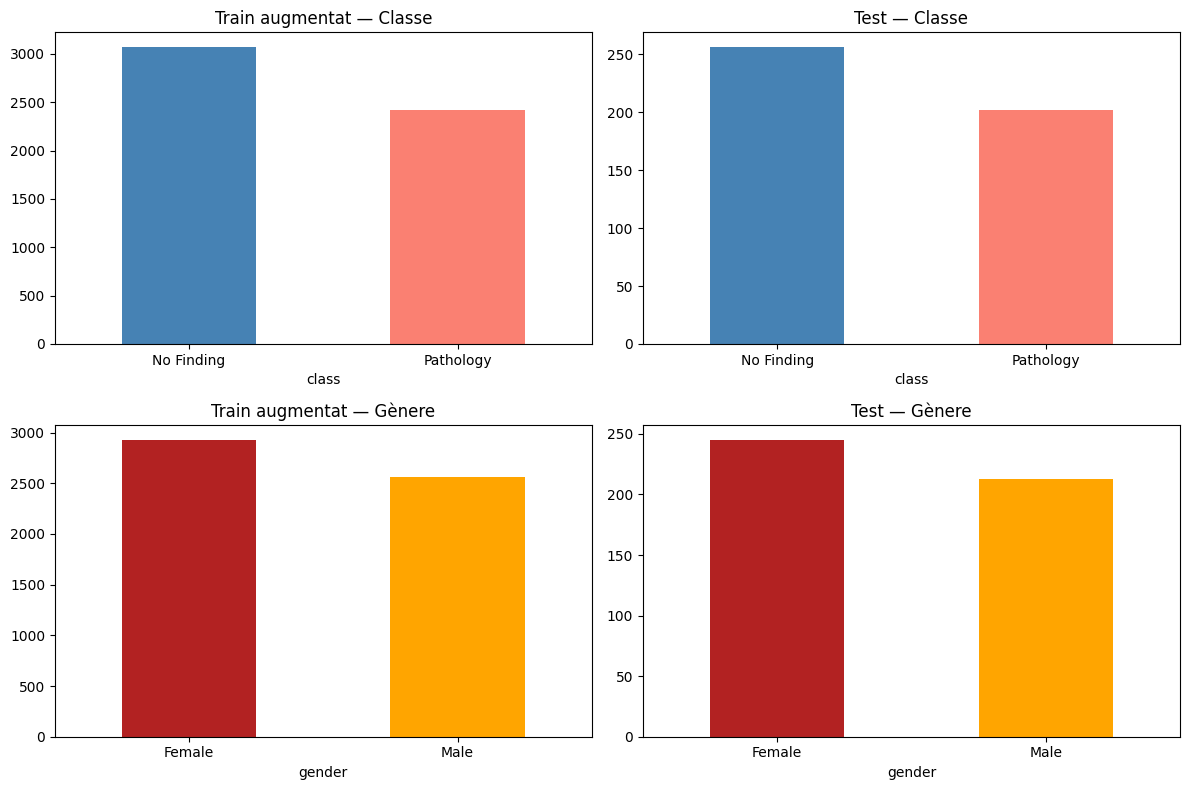

In [39]:
# Comparació distribucions originals vs augmentades
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# --- Classe ---
for ax, (title, df_plot) in zip(
    axes[0],
    [("Train augmentat — Classe", df_train_full), ("Test — Classe", df_test_out)]
):
    df_plot["class"].map(class_map).value_counts().plot(
        kind="bar", ax=ax, color=["steelblue", "salmon"]
    )
    ax.set_title(title)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# --- Gènere ---
for ax, (title, df_plot) in zip(
    axes[1],
    [("Train augmentat — Gènere", df_train_full), ("Test — Gènere", df_test_out)]
):
    df_plot["gender"].map(gender_map).value_counts().plot(
        kind="bar", ax=ax, color=["firebrick", "orange"]
    )
    ax.set_title(title)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()